# 02 — Values: Autodiff and Gradient Descent

Covers `karpathy.py` lines 19–61: the `Value` class, and the box that notebook 01
asked you to accept without opening.

None of this is specific to language models. `Value` is a general reverse-mode
automatic differentiator — swap the transformer for anything built out of the same
operations and it would work unchanged. It is the layer that makes `loss.backward()`
on line 224 a single line in notebook 03.

The reason it comes second: this is the classical machine learning the rest of the
project sits on. Every notebook after this one treats a gradient as something that
arrives; this is where it comes from, and the last two sections use nothing but
`Value` — no tokens, no model, no training loop.

Code cells reproduce the source verbatim, dedented where a fragment sits inside a
class. Anything that is *not* from the source is marked as such.

## 2.1 The `Value` node — lines 19–26

It's worth calling out what this is doing for us. We're keeping track of a value  __And its derivative__ and updating both together when we do things like multiply it by a scalar or exponentiate. This is "autodifferentiation": we get exact derivatives at the end without doing symbolic differentiation or numerical estimation. As long as we can build our algorithm out of the operations we overload for Value, at the end we'll have derivatives available.

Specifically, the "forward pass" will walk through all the computations involved in actually updating our model one time given its current state. Then, a backward pass can perform a gradient descent step and update based on the derivates we have for free after the forward step, and this step doesn't need to know anything about the model!

This happens in our overloads for the basic addition and multiplication operations, and for exponentiation and xam operations. This means any math we buidl with these will provide derivatives for free. Notice we return a new Value with the local_grads set in the operation.
Not a number — a node in a graph. Four fields: the scalar itself, a gradient slot
that starts at zero, the nodes this one was computed from, and the derivative of
this node with respect to each of them.

`_local_grads` is the design decision worth noticing. Most implementations of this
store a closure per node — a little function that knows how to propagate. Here the
local derivative is computed during the *forward* pass and stored as a plain
number, so `backward` is arithmetic over data rather than a chain of function
calls.

`__slots__` avoids a per-instance `__dict__`. A single training step on the default
model builds hundreds of thousands of these.

## 2.2 Standard operations — lines 28–34

We will overload addition and multiplication to include the partial derivative calculations, then use these for other operations and get it for free. We'll do the same for a few basic building block functions.


For $c = a + b$ the derivatives are ($\partial c/\partial a$, $\partial c/\partial b$ = $(1,1)$. For $c = a \cdot b$ they are ($\partial c/\partial a = b$,
$\partial c/\partial b = a$) — hence `(other.data, self.data)'.

We'll also want a few other derivatives available:
$$
\frac{d}{dx}x^{n} = n x^{n-1}
\qquad
\frac{d}{dx}\log x = \frac{1}{x}
\qquad
\frac{d}{dx}e^{x} = e^{x}
\qquad
\frac{d}{dx}\max(0, x) = [\,x > 0\,]
$$

These four plus `+` and `*` are the entire vocabulary of the Value `autodifferentiation`. That the entire toolbox we'll need to build, apply, and train the algorithms and models we'll need.

In [ ]:
class Value:
    __slots__ = ('data', 'grad', '_children', '_local_grads') # Python optimization for memory usage

    def __init__(self, data, children=(), local_grads=()):
        self.data = data                # scalar value of this node calculated during forward pass
        self.grad = 0                   # derivative of the loss w.r.t. this node, calculated in backward pass
        self._children = children       # children of this node in the computation graph
        self._local_grads = local_grads # local derivative of this node w.r.t. its children

def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    return Value(self.data + other.data, (self, other), (1, 1))

def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    return Value(self.data * other.data, (self, other), (other.data, self.data))

def __neg__(self): return self * -1
def __radd__(self, other): return self + other
def __sub__(self, other): return self + (-other)
def __rsub__(self, other): return other + (-self)
def __rmul__(self, other): return self * other
def __truediv__(self, other): return self * other**-1
def __rtruediv__(self, other): return other * self**-1

def __pow__(self, other): return Value(self.data**other, (self,), (other * self.data**(other-1),))
def log(self): return Value(math.log(self.data), (self,), (1/self.data,))
def exp(self): return Value(math.exp(self.data), (self,), (math.exp(self.data),))
def relu(self): return Value(max(0, self.data), (self,), (float(self.data > 0),))

## 2.5 `backward()` — lines 48–61

When we've used Values to perform some computation - generally the "Forward" pass, where we take the state at time $t$ and estimate it at time $T+1$ - we'll have left a trail of partial derivatives for each "atom" of computation involved - each operation. We then traverse this trail and gather up the total derivative at that point. This takes two stages:

**Topological sort.** A depth-first walk from the root, appending each node *after*
its children, with a `visited` set so a node reached by several paths is emitted
once. The result is an order in which every node appears after everything it was
built from.

**The reverse sweep.** Seed the root with $\partial \mathcal{L}/\partial \mathcal{L} = 1$,
walk the order backwards, and push each node's gradient down to its children:

$$
\frac{\partial \mathcal{L}}{\partial c} \;\mathrel{+}=\;
\frac{\partial v}{\partial c} \cdot \frac{\partial \mathcal{L}}{\partial v}
$$

That single line is the chain rule. Reversed topological order is what makes it
correct in one pass: when a node is processed, every path from the loss into it has
already been accounted for, so its `grad` is final before it is used.

The `+=` matters. A node used in several places — a weight touched at every
position of a document — receives a contribution from each, and they sum. It is
also why `train` must reset `p.grad = 0` on line 235: nothing here clears anything.

In [ ]:
def backward(self):
    topo = []
    visited = set()
    def build_topo(v):
        if v not in visited:
            visited.add(v)
            for child in v._children:
                build_topo(child)
            topo.append(v)
    build_topo(self)
    self.grad = 1
    for v in reversed(topo):
        for child, local_grad in zip(v._children, v._local_grads):
            child.grad += local_grad * v.grad

## 2.6 Derivatives for free

This is powerful machinery we'll use to train our embeddings and algorithms soon. First, an example: we'll define a simple cubic polynomial and run some points through it then verify we can recover the derivative since we know the analytic answer in this case.

$$
f(x) = 2x^{3} - 3x^{2} - 12x + 5
$$
Thus from Calculus I, we know:
$$
f'(x) = 6x^{2} - 6x - 12 = 6(x+1)(x-2)
$$

`f` is written once, in ordinary Python, with `Value` in place of `float`.
Evaluating it builds a graph; `backward()` walks that graph and leaves $f'(x)$ in
`x.grad`.

max |autodiff - analytic| = 7.1e-15


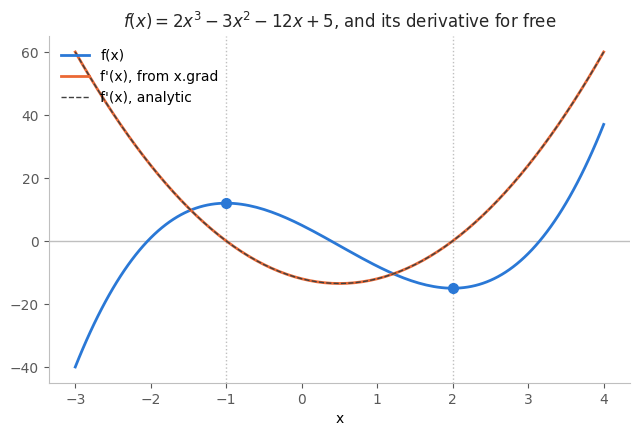

In [1]:
# Not from the source: f(x) = 2x^3 - 3x^2 - 12x + 5, differentiated by the graph itself.
import sys; sys.path.insert(0, '..')   # karpathy.py lives one level up
import matplotlib.pyplot as plt
from karpathy import Value

def f(x):
    return 2 * x**3 - 3 * x**2 - 12 * x + 5

xs, ys, dys = [i / 20 for i in range(-60, 81)], [], []   # x from -3.0 to 4.0
for xv in xs:
    x = Value(xv)      # a fresh leaf each time, so grad starts at 0
    y = f(x)           # forward: evaluate f *and* build the graph
    y.backward()       # backward: fill in df/dx
    ys.append(y.data)
    dys.append(x.grad)

analytic = [6 * xv**2 - 6 * xv - 12 for xv in xs]
print(f"max |autodiff - analytic| = {max(abs(a - b) for a, b in zip(dys, analytic)):.1e}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.axhline(0, lw=1, color='0.75', zorder=0)
for root in (-1.0, 2.0):                       # f'(x) = 0
    ax.axvline(root, lw=1, ls=':', color='0.75', zorder=0)
    ax.plot(root, f(Value(root)).data, 'o', ms=7, color='#2a78d6', zorder=3)
ax.plot(xs, ys,       lw=2, color='#2a78d6', label="f(x)")
ax.plot(xs, dys,      lw=2, color='#eb6834', label="f'(x), from x.grad")
ax.plot(xs, analytic, lw=1, ls='--', color='0.25', label="f'(x), analytic")
ax.set_xlabel('x')
ax.set_title("$f(x) = 2x^3 - 3x^2 - 12x + 5$, and its derivative for free", color='0.15')
ax.legend(frameon=False, loc='upper left')
ax.tick_params(colors='0.35')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
for side in ('left', 'bottom'):
    ax.spines[side].set_color('0.75')
plt.show()